**Unsupervised Learning Assignment**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

df.info()

Shape: (200, 5)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows:
0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [3]:
X = df[['Age', 'Annual Income (k$)',
        'Spending Score (1-100)']]

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


Feature Scaling

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)
scaled_df.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


In [5]:
print("Mean after scaling:")
print(scaled_df.mean().round(3))

print("\nStandard deviation after scaling:")
print(scaled_df.std(ddof=0).round(3))

Mean after scaling:
Age                      -0.0
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standard deviation after scaling:
Age                       1.0
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


K-Means Clustering

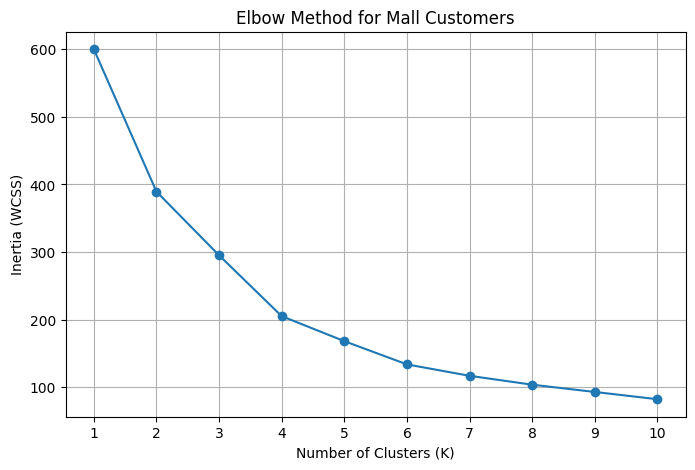

In [6]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method for Mall Customers')
plt.xticks(K_range)
plt.grid(True)
plt.show()

Applying final K-Means with K=4

In [7]:
kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans_final.fit_predict(X_scaled)
df['KMeans_Cluster'] = kmeans_labels
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


Actual Cluster Results

In [8]:
print(df['KMeans_Cluster'].value_counts().sort_index())

cluster_summary = df.groupby('KMeans_Cluster')[
    ['Age', 'Annual Income (k$)',
     'Spending Score (1-100)']
].mean().round(1)

print(cluster_summary)

KMeans_Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64
                 Age  Annual Income (k$)  Spending Score (1-100)
KMeans_Cluster                                                  
0               54.0                47.7                    40.0
1               32.9                86.1                    81.5
2               25.4                40.0                    60.3
3               39.4                86.5                    19.6


Centroids

In [10]:
print(kmeans_final.cluster_centers_)

centroids_original = scaler.inverse_transform(
    kmeans_final.cluster_centers_
)
centroid_df = pd.DataFrame(
    centroids_original,
    columns=X.columns
)
print(centroid_df.round(2))

[[ 1.08616125 -0.49056525 -0.39717443]
 [-0.42880597  0.97484722  1.21608539]
 [-0.96249203 -0.78476346  0.39202966]
 [ 0.03720536  0.99011499 -1.18875705]]
     Age  Annual Income (k$)  Spending Score (1-100)
0  53.98               47.71                   39.97
1  32.88               86.10                   81.53
2  25.44               40.00                   60.30
3  39.37               86.50                   19.58


DBSCAN Clustering

In [11]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)
dbscan_labels = dbscan.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN_Cluster
-1    60
 0    17
 1     5
 2    51
 3    28
 4    32
 5     7
Name: count, dtype: int64


Identify Outliers in DBSCAN

In [12]:
outliers = df[df['DBSCAN_Cluster'] == -1]
print("Number of outliers:", len(outliers))
outliers.head()

Number of outliers: 60


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster,DBSCAN_Cluster
0,1,Male,19,15,39,2,-1
2,3,Female,20,16,6,2,-1
4,5,Female,31,17,40,2,-1
6,7,Female,35,18,6,0,-1
7,8,Female,23,18,94,2,-1


In [13]:
noise_percentage = (
    len(outliers) / len(df)
) * 100
print(f"Noise percentage: {noise_percentage:.1f}%")

Noise percentage: 30.0%


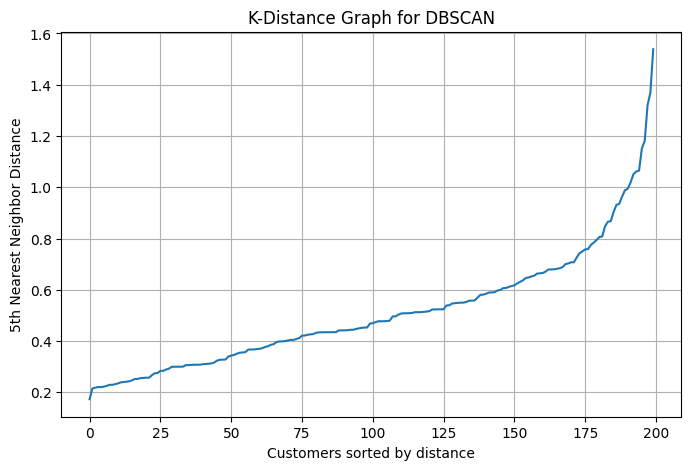

In [14]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)
distances, indices = neighbors.kneighbors(X_scaled)
k_distances = distances[:, 4]
k_distances = np.sort(k_distances)

plt.figure(figsize=(8, 5))
plt.plot(k_distances)

plt.xlabel("Customers sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

comparing different eps values

In [15]:
for eps_value in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:

    model = DBSCAN(
        eps=eps_value,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    n_noise = np.sum(labels == -1)

    print(
        f"eps={eps_value:.1f} | "
        f"Clusters={n_clusters} | "
        f"Noise={n_noise}"
    )

eps=0.3 | Clusters=10 | Noise=134
eps=0.4 | Clusters=6 | Noise=98
eps=0.5 | Clusters=6 | Noise=60
eps=0.6 | Clusters=2 | Noise=28
eps=0.7 | Clusters=1 | Noise=14
eps=0.8 | Clusters=1 | Noise=6


DBSCAN using silhouette score

In [16]:
from sklearn.metrics import silhouette_score

results = []

for eps_value in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    for min_pts in [4, 5, 6, 8]:

        model = DBSCAN(
            eps=eps_value,
            min_samples=min_pts
        )

        labels = model.fit_predict(X_scaled)

        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        n_noise = np.sum(~mask)

        # Silhouette needs at least 2 clusters
        # and fewer clusters than included samples
        if 2 <= n_clusters < mask.sum():

            score = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )

            results.append([
                eps_value,
                min_pts,
                n_clusters,
                n_noise,
                score
            ])

results_df = pd.DataFrame(
    results,
    columns=[
        'eps',
        'min_samples',
        'clusters',
        'noise',
        'silhouette'
    ]
)

print(
    results_df.sort_values(
        'silhouette',
        ascending=False
    ).head(10)
)

    eps  min_samples  clusters  noise  silhouette
6   0.4            8         3    145    0.678151
2   0.3            6         5    164    0.671171
5   0.4            6         6    110    0.558444
9   0.5            6         5     66    0.527767
4   0.4            5         6     98    0.519023
1   0.3            5        10    134    0.514353
10  0.5            8         5     92    0.504565
0   0.3            4         7    121    0.496808
8   0.5            5         6     60    0.481715
14  0.6            8         4     52    0.473590


In [17]:
core_indices = dbscan.core_sample_indices_

# Create a mask for core points
is_core = np.zeros(len(X_scaled), dtype=bool)
is_core[core_indices] = True

# Identify the three point types
point_types = np.where(
    dbscan_labels == -1,
    'Noise',
    np.where(is_core, 'Core', 'Border')
)

df['DBSCAN_Point_Type'] = point_types

print(df['DBSCAN_Point_Type'].value_counts())

DBSCAN_Point_Type
Core      109
Noise      60
Border     31
Name: count, dtype: int64


PCA Dimensionality Reduction and Visualization

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

print(X_pca[:5])

Original shape: (200, 3)
PCA shape: (200, 2)
[[-0.61572002 -1.76348088]
 [-1.66579271 -1.82074695]
 [ 0.33786191 -1.67479894]
 [-1.45657325 -1.77242992]
 [-0.03846521 -1.66274012]]


Explained Variance

In [19]:
explained_variance = pca.explained_variance_ratio_

print("PC1:", explained_variance[0])
print("PC2:", explained_variance[1])

print(
    "Total explained variance:",
    explained_variance.sum()
)

PC1: 0.4426616720824504
PC2: 0.33308378461522425
Total explained variance: 0.7757454566976747


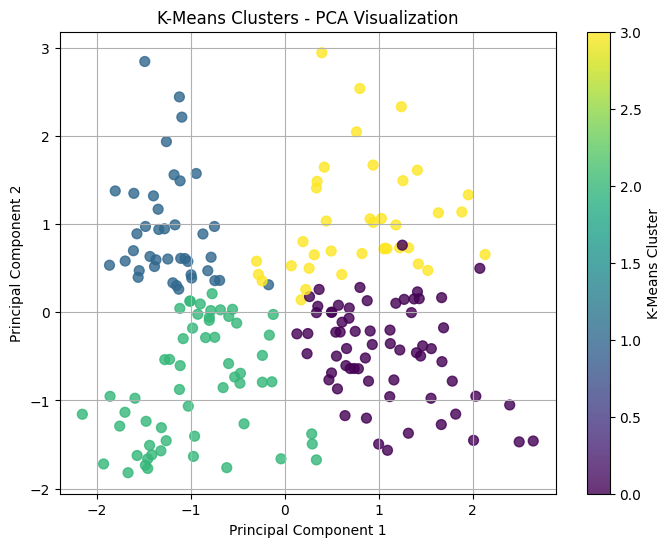

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=50,
    alpha=0.8
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters - PCA Visualization')

plt.colorbar(label='K-Means Cluster')
plt.grid(True)
plt.show()

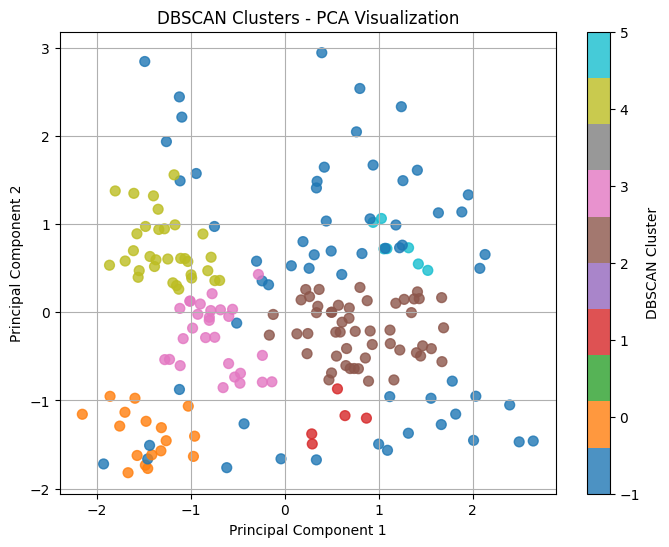

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='tab10',
    s=50,
    alpha=0.8
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clusters - PCA Visualization')

plt.colorbar(label='DBSCAN Cluster')
plt.grid(True)
plt.show()

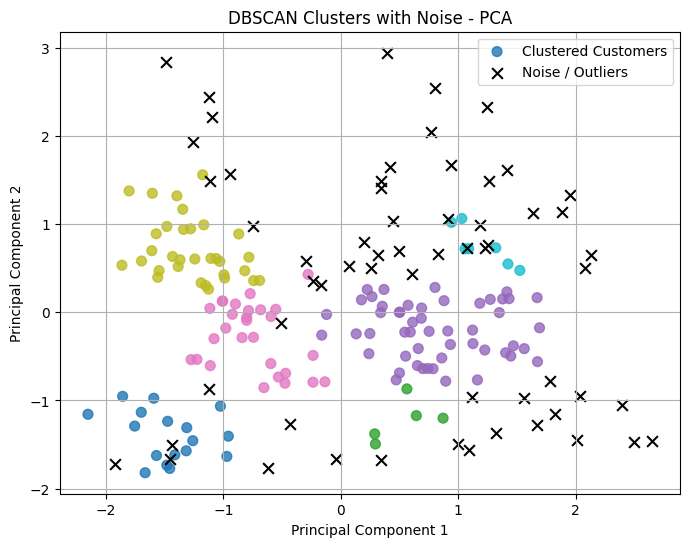

In [22]:
plt.figure(figsize=(8, 6))

cluster_mask = dbscan_labels != -1
noise_mask = dbscan_labels == -1

plt.scatter(
    X_pca[cluster_mask, 0],
    X_pca[cluster_mask, 1],
    c=dbscan_labels[cluster_mask],
    cmap='tab10',
    s=50,
    alpha=0.8,
    label='Clustered Customers'
)

plt.scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    c='black',
    marker='x',
    s=60,
    label='Noise / Outliers'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clusters with Noise - PCA')

plt.legend()
plt.grid(True)
plt.show()

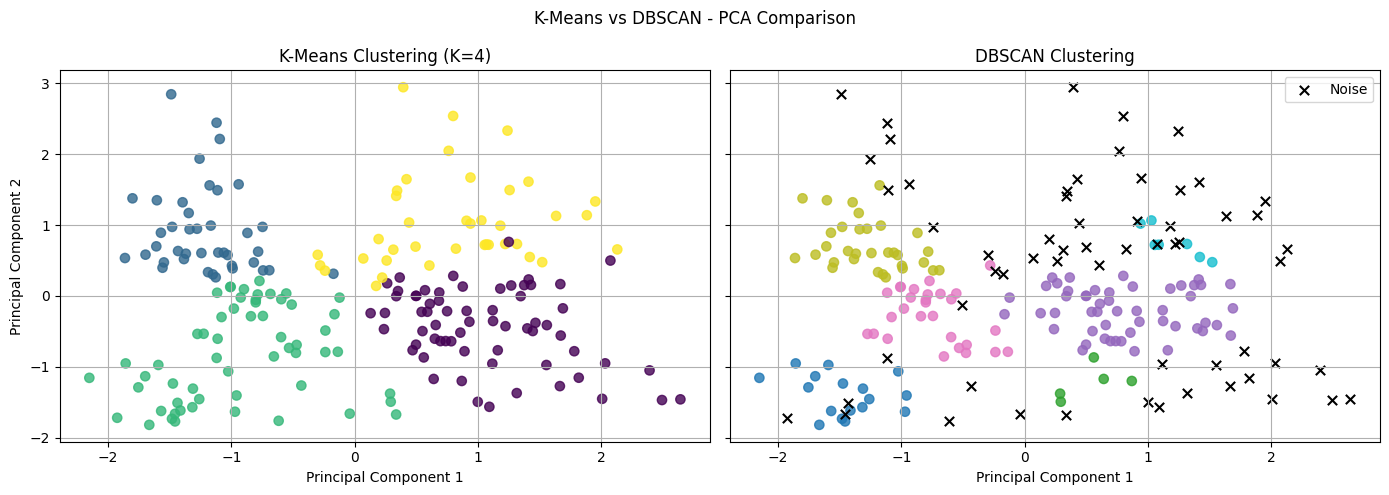

In [23]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

# K-Means plot
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=45,
    alpha=0.8
)

axes[0].set_title('K-Means Clustering (K=4)')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].grid(True)

# DBSCAN plot
cluster_mask = dbscan_labels != -1
noise_mask = dbscan_labels == -1

axes[1].scatter(
    X_pca[cluster_mask, 0],
    X_pca[cluster_mask, 1],
    c=dbscan_labels[cluster_mask],
    cmap='tab10',
    s=45,
    alpha=0.8
)

axes[1].scatter(
    X_pca[noise_mask, 0],
    X_pca[noise_mask, 1],
    c='black',
    marker='x',
    s=45,
    label='Noise'
)

axes[1].set_title('DBSCAN Clustering')
axes[1].set_xlabel('Principal Component 1')
axes[1].legend()
axes[1].grid(True)

plt.suptitle('K-Means vs DBSCAN - PCA Comparison')
plt.tight_layout()
plt.show()

**Conclusion**

This assignment applied two unsupervised clustering algorithms to 200 mall customers using Age, Annual Income, and Spending Score. After standardizing the features, K-Means with K=4 produced four interpretable customer segments, while DBSCAN with eps=0.5 and min_samples=5 identified density-based groups and marked some customers as noise. PCA reduced the three standardized features to two components for a shared visualization, retaining approximately 77.6% of total variance. K-Means provided a complete segmentation of all customers, whereas DBSCAN highlighted sparse observations; the preferred algorithm depends on whether the business values complete grouping or explicit noise detection.